# 03 · Ingeniería de Características y Partición Muestral

## Variables de Comportamiento Pre-Default
Todas las variables deben medirse estrictamente en la fecha de corte $t$:
1. `utilization_obs`: Tasa de uso inicial ($B_t / L_t$).
2. `log_credit_limit`: Escala logarítmica del límite.
3. `income_to_limit`: Capacidad económica frente al compromiso crediticio.
4. `util_tier`: Tramos regulatorios de uso ($<20\%$, $20-50\%$, $50-80\%$, $>80\%$).
5. `risk_interaction`: Interacción entre uso previo y morosidad.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

plt.style.use('seaborn-v0_8-whitegrid')

raw_path = Path("../data/raw/revolving_ccf_portfolio.csv")
df = pd.read_csv(raw_path)
defaulted = df.query("default_flag == 1").dropna(subset=['realized_leq']).copy()
print(f"Población de modelado: {len(defaulted):,} contratos.")

Población de modelado: 1,255 contratos.


In [2]:
# Construcción de variables predictoras
defaulted['log_credit_limit'] = np.log(defaulted['credit_limit'])
defaulted['income_to_limit'] = defaulted['annual_income'] / defaulted['credit_limit']
defaulted['util_sq'] = defaulted['utilization_obs'] ** 2

# Indicador de mora previa
defaulted['is_delinquent'] = (defaulted['delinquency_bucket'] != '0 DPD').astype(int)
defaulted['util_delinq_inter'] = defaulted['utilization_obs'] * defaulted['is_delinquent']

# Tramos de utilización previa
defaulted['util_tier'] = pd.cut(
    defaulted['utilization_obs'],
    bins=[-np.inf, 0.20, 0.50, 0.80, np.inf],
    labels=["Baja_<20%", "Media_20-50%", "Alta_50-80%", "CasiAgotada_>80%"]
)

display(defaulted[['account_id', 'credit_limit', 'utilization_obs', 'util_tier', 'realized_leq']].head())

,account_id,credit_limit,utilization_obs,util_tier,realized_leq
16,ACC_100017,6000.0,0.2305,Media_20-50%,0.6050
22,ACC_100023,6000.0,0.8131,CasiAgotada_>80%,0.5454
32,ACC_100033,3500.0,0.6828,Alta_50-80%,1.0447
35,ACC_100036,6500.0,0.5565,Alta_50-80%,1.0317
75,ACC_100076,15000.0,0.4540,Media_20-50%,0.4614


C:\Users\jhon_\AppData\Local\Temp\ipykernel_24692\923532664.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tier_summary, x='util_tier', y='mean_leq', palette='Greens_d', ax=ax)


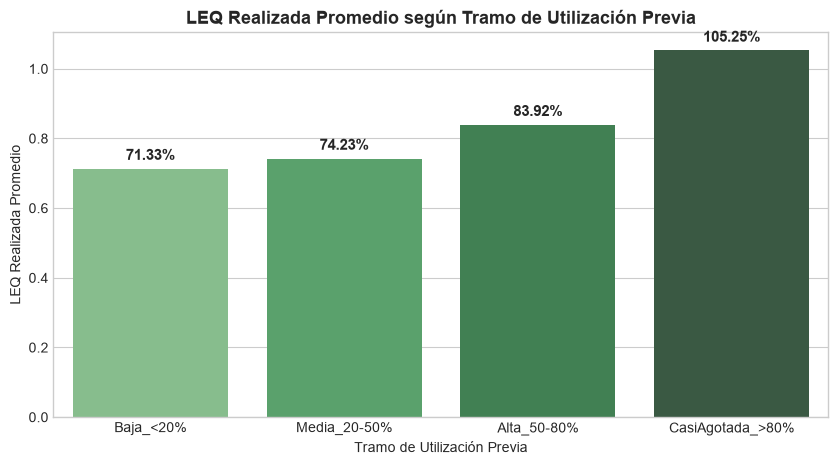

,util_tier,count,mean_leq,median_leq,std_leq
0,Baja_<20%,72,0.713321,0.79370,0.219436
1,Media_20-50%,454,0.742349,0.76880,0.216080
2,Alta_50-80%,601,0.839246,0.86650,0.203373
3,CasiAgotada_>80%,128,1.052516,1.08995,0.218062


In [3]:
# Análisis de LEQ por Tramo de Utilización Previa
tier_summary = defaulted.groupby('util_tier', observed=True)['realized_leq'].agg(
    count='count',
    mean_leq='mean',
    median_leq='median',
    std_leq='std'
).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=tier_summary, x='util_tier', y='mean_leq', palette='Greens_d', ax=ax)
ax.set_title("LEQ Realizada Promedio según Tramo de Utilización Previa", fontsize=13, fontweight='bold')
ax.set_xlabel("Tramo de Utilización Previa")
ax.set_ylabel("LEQ Realizada Promedio")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 4), textcoords='offset points')
plt.show()

display(tier_summary)

In [4]:
# Partición Train/Test (80/20 Estratificada por Producto)
MODEL_FEATURES = [
    'credit_limit', 'balance_obs', 'utilization_obs', 'credit_score',
    'months_on_book', 'annual_income', 'payment_ratio', 'log_credit_limit',
    'income_to_limit', 'util_sq', 'is_delinquent', 'util_delinq_inter'
]
TARGET = "realized_leq"

X_train, X_test, y_train, y_test = train_test_split(
    defaulted[MODEL_FEATURES + ['product_type', 'ead_at_default']],
    defaulted[TARGET],
    test_size=0.20,
    random_state=42,
    stratify=defaulted['product_type']
)

print(f"Muestra de Entrenamiento: {len(X_train):,} ({len(X_train)/len(defaulted):.0%})")
print(f"Muestra de Validación:    {len(X_test):,} ({len(X_test)/len(defaulted):.0%})")
print(f"LEQ Media Train: {y_train.mean():.4f} | Test: {y_test.mean():.4f}")

Muestra de Entrenamiento: 1,004 (80%)
Muestra de Validación:    251 (20%)
LEQ Media Train: 0.8153 | Test: 0.8326


In [5]:
# Exportar particiones procesadas
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

train_df.to_csv(processed_dir / "ccf_train.csv", index=False)
test_df.to_csv(processed_dir / "ccf_test.csv", index=False)
print("Particiones guardadas en CCF/data/processed.")

Particiones guardadas en CCF/data/processed.


## Próximo Paso
* **Siguiente Cuaderno**: [04_ccf_model.ipynb](file:///c:/Users/jhon_/Documents/GitHub/IFRS9-Credit-Risk/CCF/notebooks/04_ccf_model.ipynb) entrena los modelos y evalúa el error monetario en dólares de exposición.